In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [54]:
df = pd.read_csv('/Users/hariharajujjarapu/Desktop/Learnings/pytorch-learning/Berlin_wind_multiclass 1(in).csv')

In [55]:
df.head()

,Year,Month,Day,Hour,Minute,Temperature,Clearsky.DHI,Clearsky.DNI,Clearsky.GHI,Cloud.Type,...,GHI,Ozone,Relative.Humidity,Solar.Zenith.Angle,Surface.Albedo,Pressure,Precipitable.Water,Wind.Direction,Wind.Speed,X50Hertz..MW.
0,2018,1,1,0,0,7.9,0,0,0,7,...,0,0.287,93.39,148.97,0.12,993,1.9,212,5.6,713.29
1,2018,1,1,0,15,7.9,0,0,0,8,...,0,0.287,93.39,147.97,0.12,993,1.9,213,5.7,701.46
2,2018,1,1,0,30,7.8,0,0,0,8,...,0,0.286,94.03,146.76,0.12,993,2.0,214,5.8,701.96
3,2018,1,1,0,45,7.7,0,0,0,7,...,0,0.286,91.31,145.35,0.12,993,2.0,214,5.8,733.83
4,2018,1,1,1,0,7.7,0,0,0,7,...,0,0.286,91.31,143.78,0.12,993,2.0,215,5.9,753.35


In [56]:
df.describe()

,Year,Month,Day,Hour,Minute,Temperature,Clearsky.DHI,Clearsky.DNI,Clearsky.GHI,Cloud.Type,...,GHI,Ozone,Relative.Humidity,Solar.Zenith.Angle,Surface.Albedo,Pressure,Precipitable.Water,Wind.Direction,Wind.Speed,X50Hertz..MW.
count,70080.000000,70080.000000,70080.000000,70080.000000,70080.000000,70080.000000,70080.000000,70080.000000,70080.000000,70080.000000,...,70080.000000,70080.000000,70080.000000,70080.000000,70080.000000,70080.000000,70080.000000,70080.000000,70080.000000,70080.000000
mean,2018.500000,6.526027,15.720548,11.500000,22.500000,10.998749,46.711416,287.289341,186.747574,3.286915,...,112.949458,0.330587,76.790341,89.613915,0.142918,1010.147432,1.734279,197.289284,3.027723,146.558898
std,0.500004,3.447876,8.796310,6.922236,16.770629,9.262004,58.534119,331.016543,259.213876,2.744254,...,201.424943,0.046931,20.664916,29.681588,0.098797,9.436679,0.858475,91.636527,1.593256,149.127427
min,2018.000000,1.000000,1.000000,0.000000,0.000000,-14.200000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.218000,14.940000,29.120000,0.100000,974.000000,0.200000,0.000000,0.100000,0.000000
25%,2018.000000,4.000000,8.000000,5.750000,11.250000,3.500000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.297000,61.727500,68.007500,0.120000,1005.000000,1.000000,115.000000,1.800000,42.000000
50%,2018.500000,7.000000,16.000000,11.500000,22.500000,10.200000,0.000000,0.000000,0.000000,4.000000,...,0.000000,0.326000,83.085000,89.250000,0.130000,1011.000000,1.600000,213.000000,2.800000,96.530000
75%,2019.000000,10.000000,23.000000,17.250000,33.750000,18.200000,89.000000,630.000000,332.000000,6.000000,...,133.000000,0.356000,94.810000,111.180000,0.140000,1016.000000,2.300000,273.000000,4.000000,196.360000
max,2019.000000,12.000000,31.000000,23.000000,45.000000,37.700000,374.000000,956.000000,917.000000,12.000000,...,912.000000,0.500000,100.000000,150.890000,0.870000,1040.000000,5.000000,360.000000,11.000000,1026.960000


In [57]:
df.isnull().sum()

Year                  0
Month                 0
Day                   0
Hour                  0
Minute                0
Temperature           0
Clearsky.DHI          0
Clearsky.DNI          0
Clearsky.GHI          0
Cloud.Type            0
Dew.Point             0
DHI                   0
DNI                   0
Fill.Flag             0
GHI                   0
Ozone                 0
Relative.Humidity     0
Solar.Zenith.Angle    0
Surface.Albedo        0
Pressure              0
Precipitable.Water    0
Wind.Direction        0
Wind.Speed            0
X50Hertz..MW.         0
dtype: int64

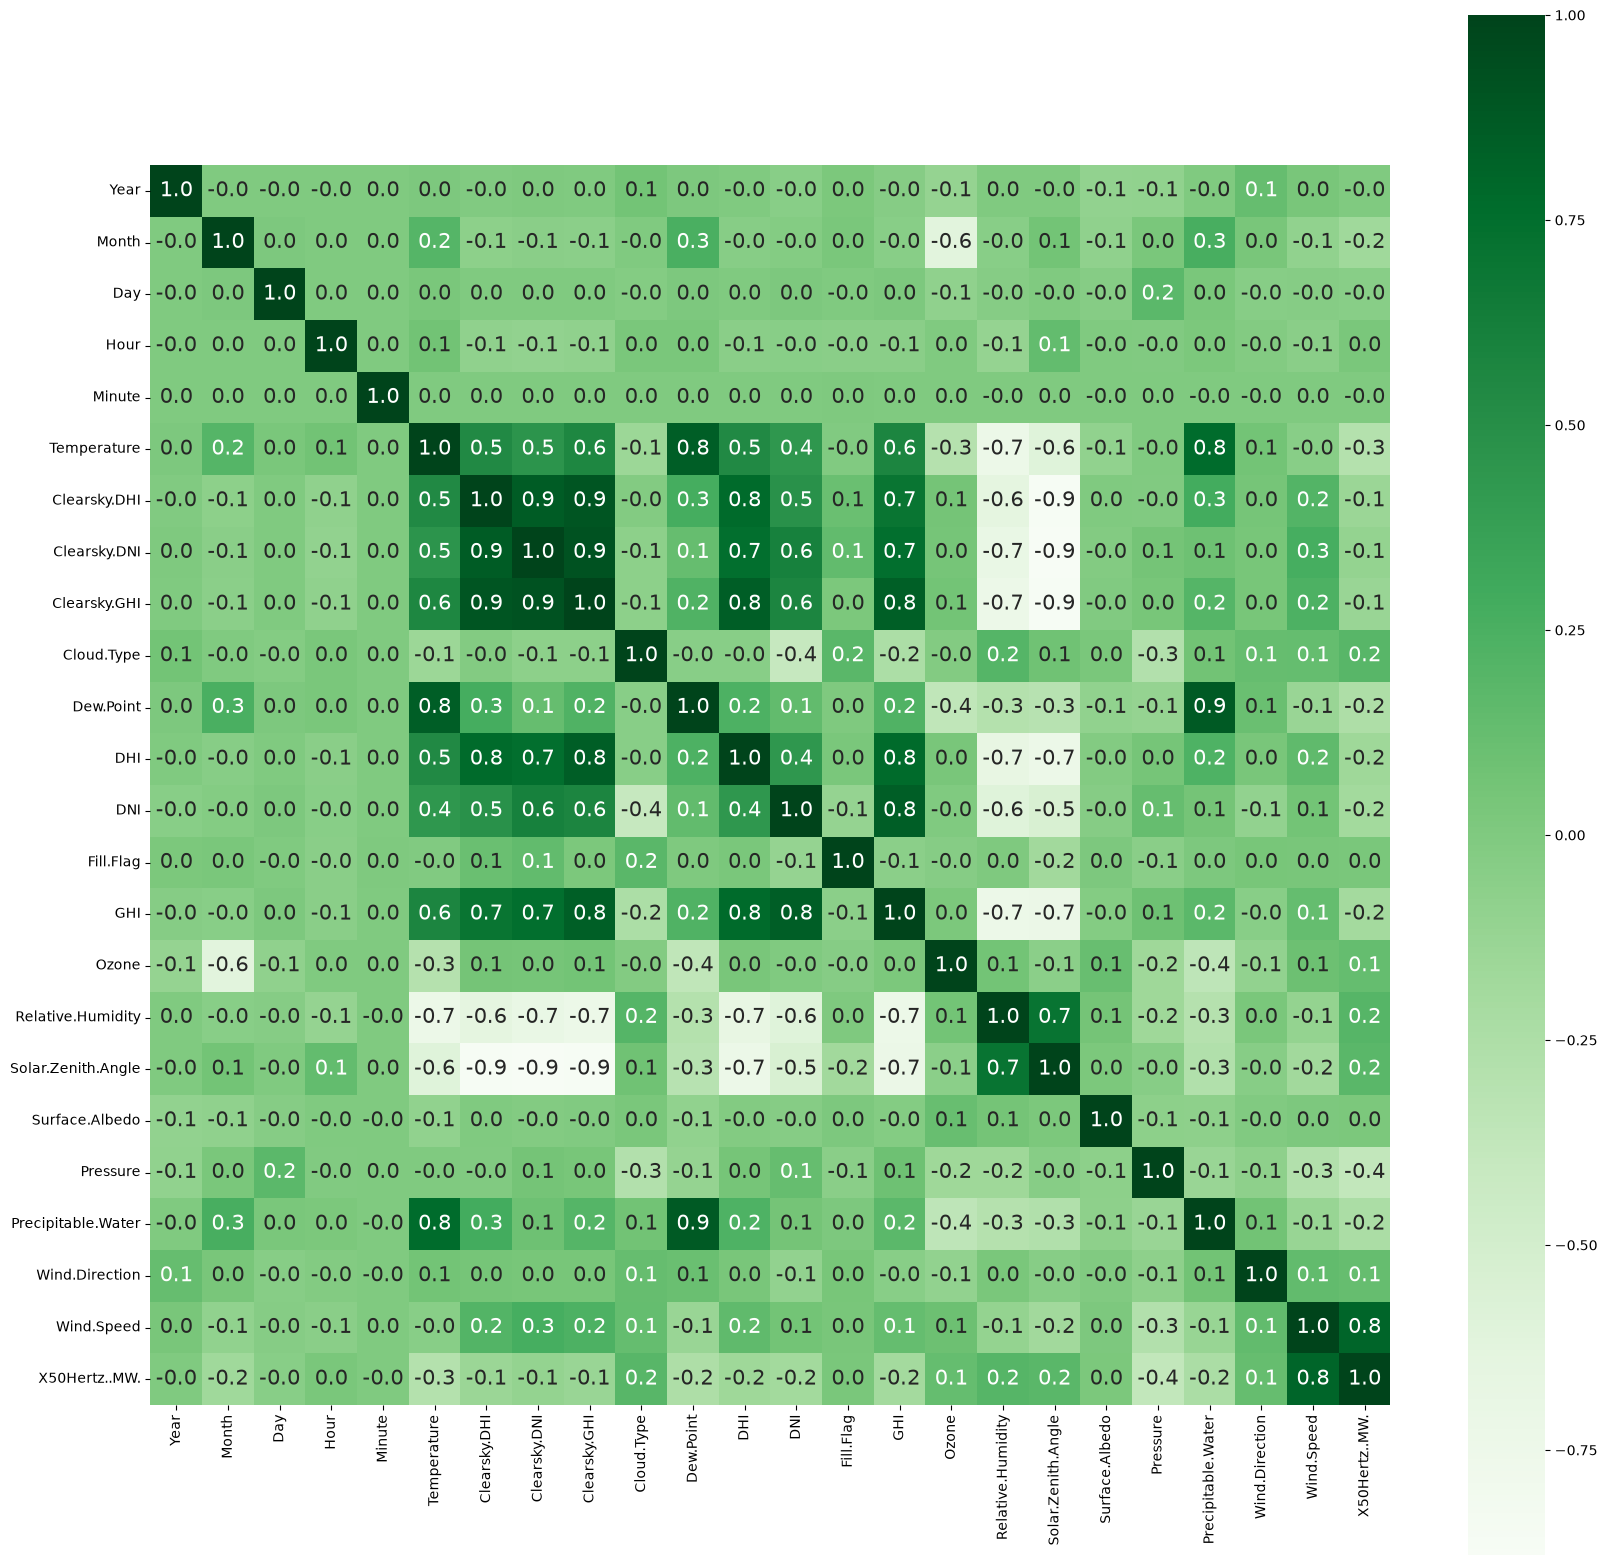

In [58]:
corr = df.corr()
plt.figure(figsize=(20, 20))
sns.heatmap(corr, 
						square=True,
						annot=True, 
						annot_kws={'size':15}, 
						fmt='.1f', 
						cmap='Greens')
plt.show()

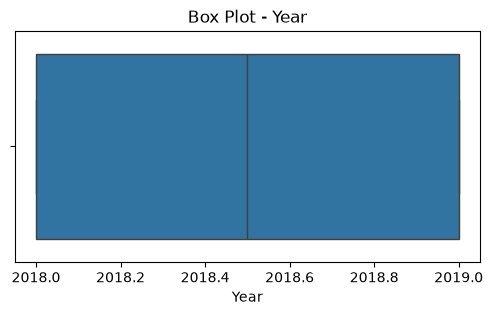

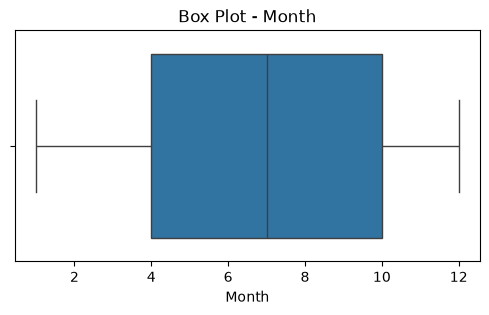

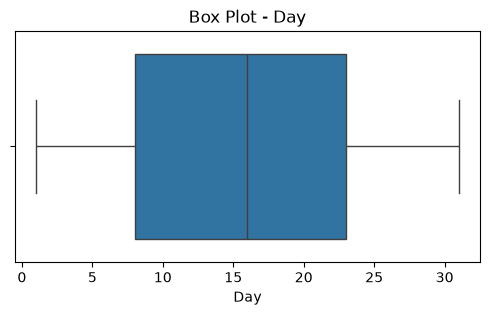

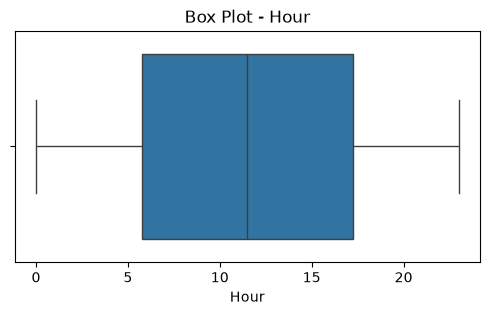

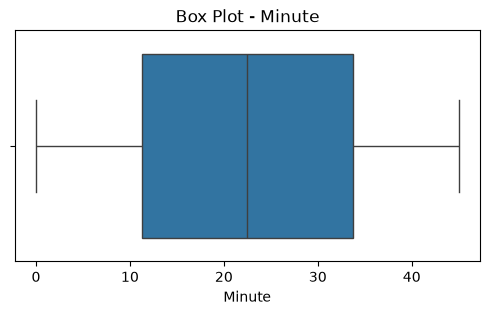

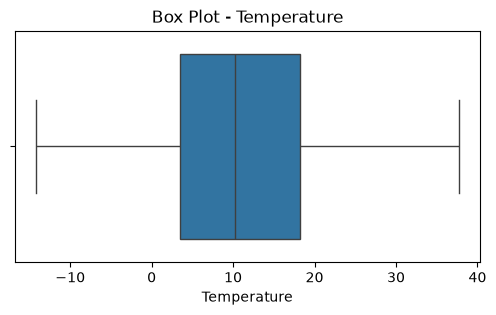

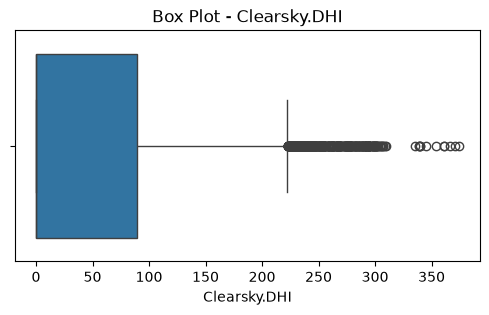

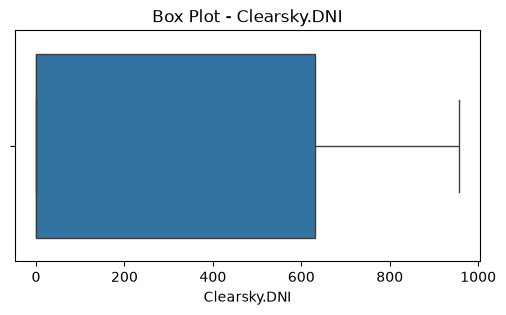

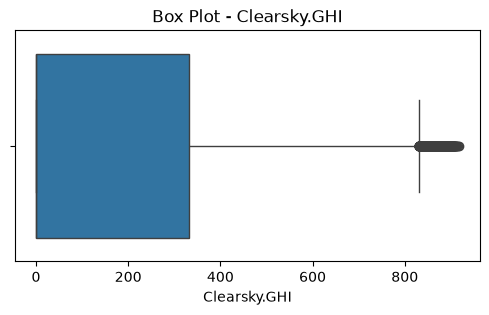

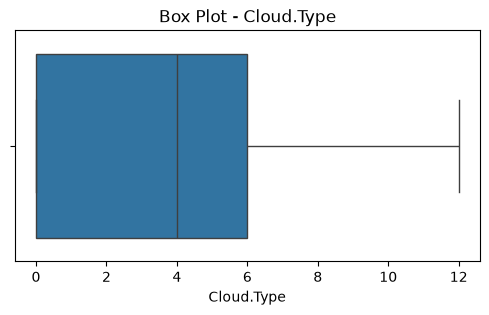

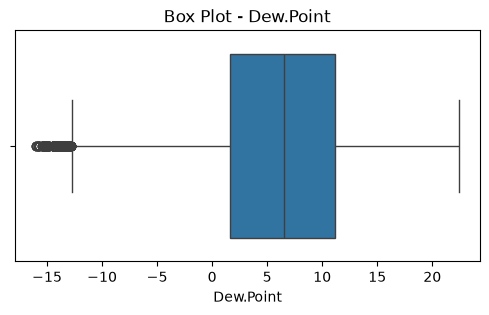

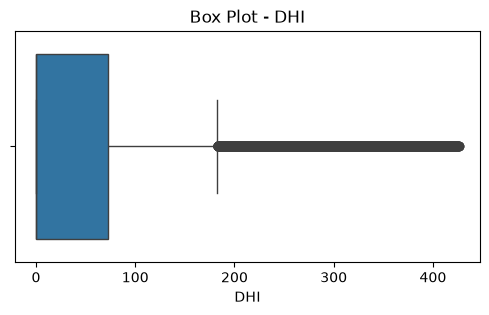

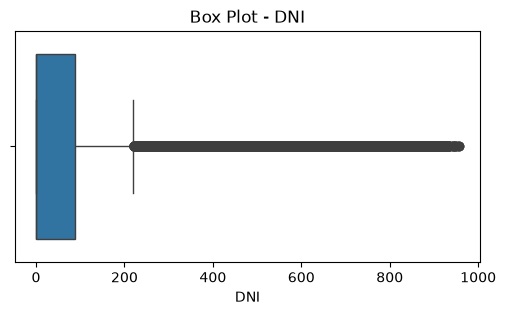

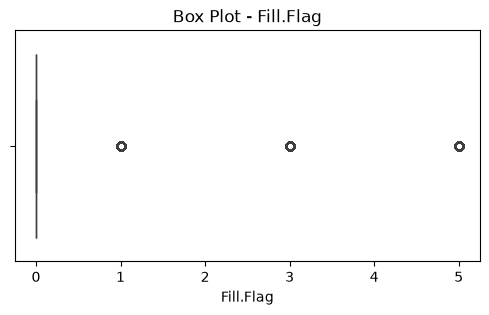

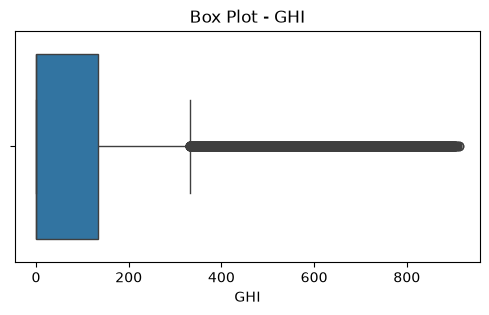

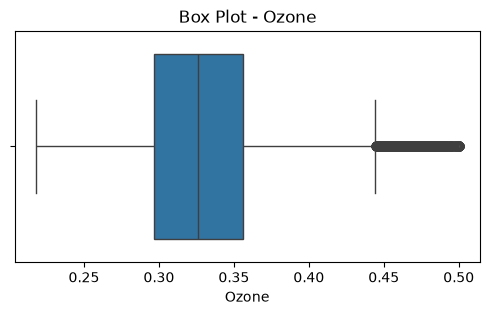

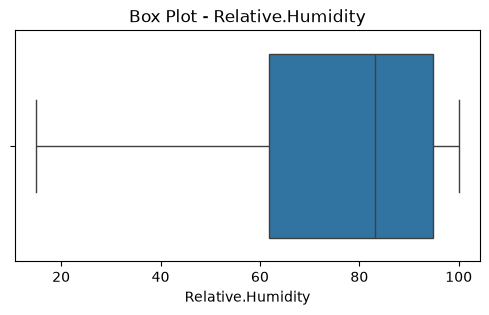

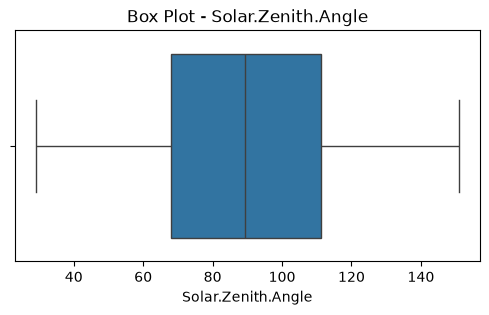

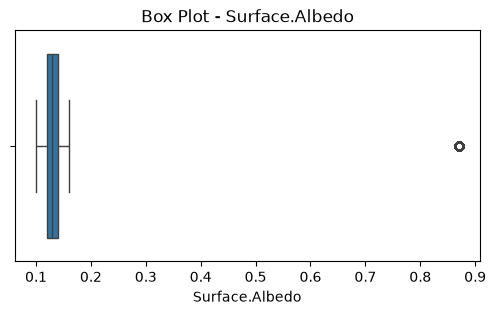

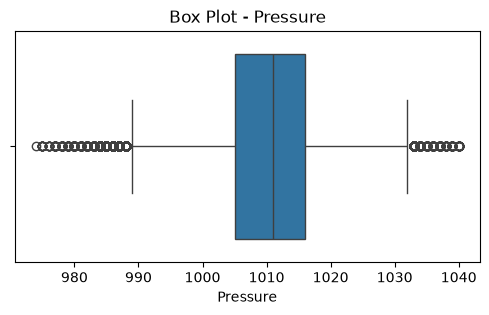

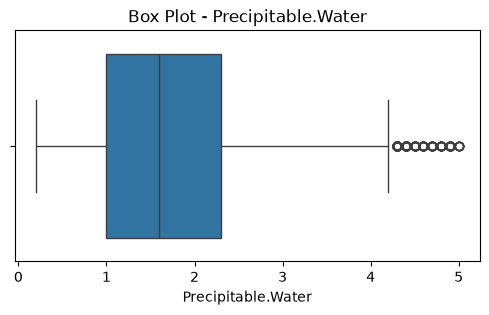

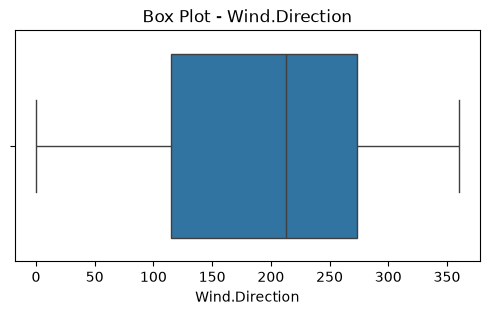

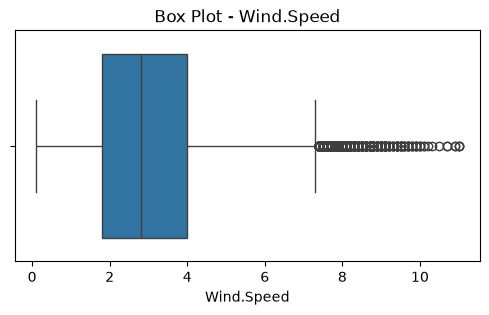

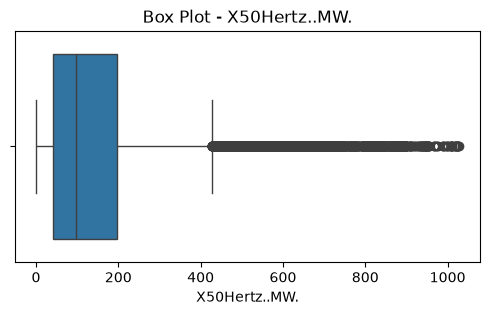

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = df.select_dtypes(include='number').columns

for col in num_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot - {col}")
    plt.show()

In [60]:
target = 'X50Hertz..MW.'

df['target'] = pd.qcut(
    df[target].rank(method='first'),
    q=5,
    labels=[0, 1, 2, 3, 4]
).astype(int)

print(df['target'].value_counts().sort_index())

target
0    14016
1    14016
2    14016
3    14016
4    14016
Name: count, dtype: int64


In [61]:
df.drop(columns=['X50Hertz..MW.'], inplace=True)

In [62]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

In [63]:
df

,Year,Month,Day,Hour,Minute,Temperature,Clearsky.DHI,Clearsky.DNI,Clearsky.GHI,Cloud.Type,...,GHI,Ozone,Relative.Humidity,Solar.Zenith.Angle,Surface.Albedo,Pressure,Precipitable.Water,Wind.Direction,Wind.Speed,target
0,2018,4,30,17,15,15.1,47,474,131,0,...,131,0.355,75.13,79.83,0.13,999,1.3,233,2.4,3
1,2019,2,13,1,0,1.7,0,0,0,7,...,0,0.312,97.68,136.24,0.12,1025,1.4,250,4.0,4
2,2019,3,21,8,0,8.9,114,607,360,4,...,28,0.305,91.82,66.02,0.12,1029,2.0,245,2.8,1
3,2018,10,9,22,0,10.6,0,0,0,7,...,0,0.267,100.00,132.68,0.12,1018,2.2,179,1.4,1
4,2018,6,7,0,30,11.6,0,0,0,0,...,0,0.354,67.55,102.51,0.15,1013,1.7,106,3.2,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70075,2019,1,23,10,30,-3.9,71,725,286,4,...,26,0.378,71.74,72.70,0.12,1000,0.3,117,4.6,2
70076,2018,3,7,6,15,-0.4,31,41,34,4,...,4,0.406,95.20,85.39,0.13,987,1.3,334,0.6,0
70077,2019,7,26,17,30,27.6,56,481,163,0,...,163,0.313,36.31,77.17,0.15,1006,2.6,53,3.1,3
70078,2018,1,9,23,0,1.3,0,0,0,9,...,0,0.373,100.00,149.35,0.12,1009,1.9,143,2.4,3


In [64]:
from sklearn.model_selection import train_test_split

X = df.iloc[:, :-1]
y = df.iloc[:, -1]          # Series (not DataFrame), what most models expect

# 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Split the 30% in half: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(len(X_train), len(X_val), len(X_test))

49056 10512 10512


In [65]:
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   " y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  " y_test: ", y_test.shape)

X_train: (49056, 23)  y_train: (49056,)
X_val:   (10512, 23)  y_val:   (10512,)
X_test:  (10512, 23)  y_test:  (10512,)


In [66]:
import xgboost as xgb

In [ ]:
# Training a centralized XGBoost Model
dtrain = xgb.DMatrix(X_train, label=y_train)
dval = xgb.DMatrix(X_val, label=y_val)
dtest = xgb.DMatrix(X_test, label=y_test)

In [89]:
# Define parameters
param = {
    'max_depth': 4,
    'eta': 0.2,
    'objective': 'multi:softmax',
    'num_class': 5,
    'eval_metric': 'merror'
}

evallist = [
    (dtrain, 'train'),
    (dtest, 'eval')
]

In [90]:
# Training the model
num_round = 2000

bst = xgb.train(param, dtrain, num_round, evallist)

[0]	train-merror:0.44565	eval-merror:0.44359


[1]	train-merror:0.41877	eval-merror:0.42589
[2]	train-merror:0.41131	eval-merror:0.41743
[3]	train-merror:0.40378	eval-merror:0.41248
[4]	train-merror:0.39551	eval-merror:0.40459
[5]	train-merror:0.39422	eval-merror:0.40202
[6]	train-merror:0.38907	eval-merror:0.39821
[7]	train-merror:0.38173	eval-merror:0.39098
[8]	train-merror:0.37832	eval-merror:0.38775
[9]	train-merror:0.37598	eval-merror:0.38803
[10]	train-merror:0.37247	eval-merror:0.38394
[11]	train-merror:0.37131	eval-merror:0.38499
[12]	train-merror:0.36727	eval-merror:0.37861
[13]	train-merror:0.36379	eval-merror:0.37548
[14]	train-merror:0.36387	eval-merror:0.37652
[15]	train-merror:0.35922	eval-merror:0.37338
[16]	train-merror:0.35565	eval-merror:0.37119
[17]	train-merror:0.35278	eval-merror:0.36596
[18]	train-merror:0.35233	eval-merror:0.36777
[19]	train-merror:0.34950	eval-merror:0.36416
[20]	train-merror:0.34722	eval-merror:0.35902
[21]	train-merror:0.34291	eval-merror:0.35531
[22]	train-merror:0.33849	eval-merror:0.349